In [1]:
import pandas as pd
df = pd.read_csv("../data/raw/students.csv")
print(df.shape)
print(df["status"].value_counts())
df.head()

(215, 15)
status
Placed        148
Not Placed     67
Name: count, dtype: int64


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


In [2]:
df.info()
print(df.isna().sum())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    str    
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    str    
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    str    
 6   hsc_s           215 non-null    str    
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    str    
 9   workex          215 non-null    str    
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    str    
 12  mba_p           215 non-null    float64
 13  status          215 non-null    str    
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), str(8)
memory usage: 35.0 KB
sl_no              0
gender             0
ssc_p              0
ssc_b              

In [3]:
print(df.shape)
print(df["status"].value_counts())

(215, 15)
status
Placed        148
Not Placed     67
Name: count, dtype: int64


In [4]:
df = df.drop(columns=["salary", "sl_no"])
df["placed"] = (df["status"] == "Placed").astype(int)
df = df.drop(columns=["status"])
print(df.shape)
df.head()


(215, 13)


,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,placed
0,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,1
1,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,1
2,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,1
3,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,0
4,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,1


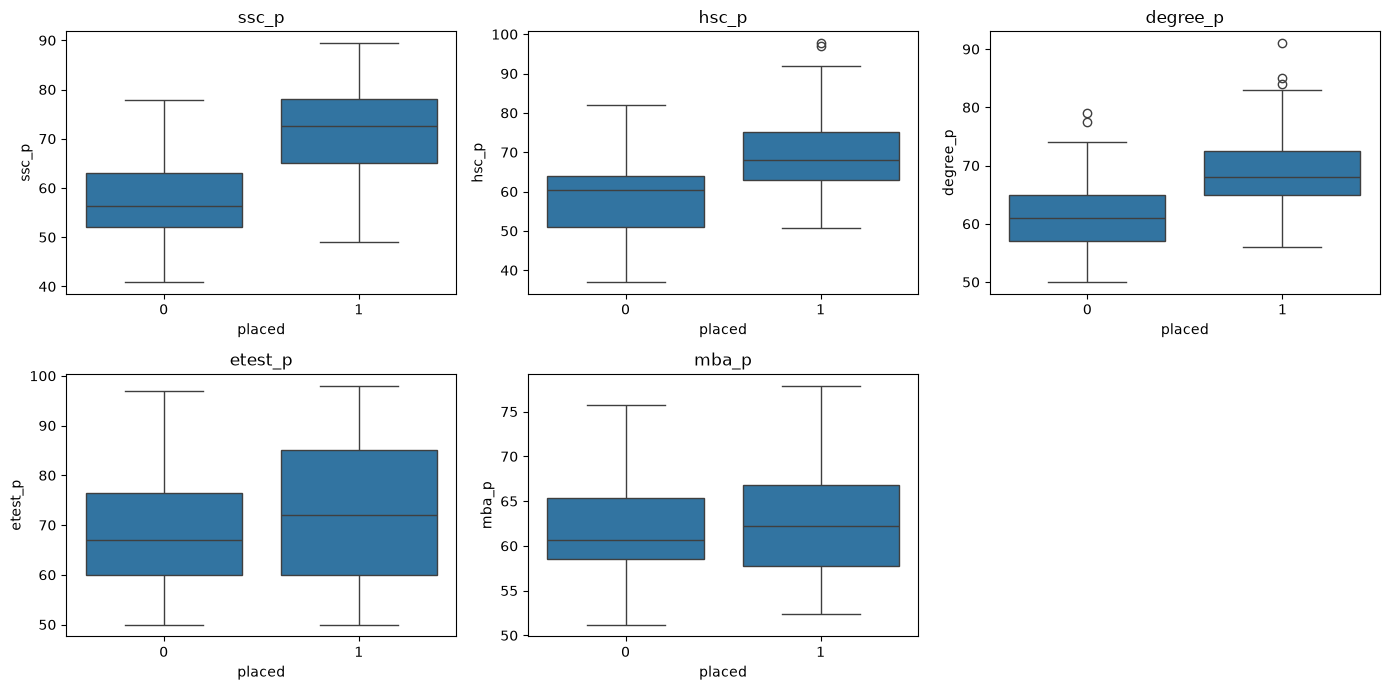

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ["ssc_p", "hsc_p", "degree_p", "etest_p", "mba_p"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="placed", y=col, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

gender
F    0.63
M    0.72
Name: placed, dtype: float64 

ssc_b
Central    0.67
Others     0.71
Name: placed, dtype: float64 

hsc_b
Central    0.68
Others     0.69
Name: placed, dtype: float64 

hsc_s
Arts        0.55
Commerce    0.70
Science     0.69
Name: placed, dtype: float64 

degree_t
Comm&Mgmt    0.70
Others       0.45
Sci&Tech     0.69
Name: placed, dtype: float64 

workex
No     0.60
Yes    0.86
Name: placed, dtype: float64 

specialisation
Mkt&Fin    0.79
Mkt&HR     0.56
Name: placed, dtype: float64 



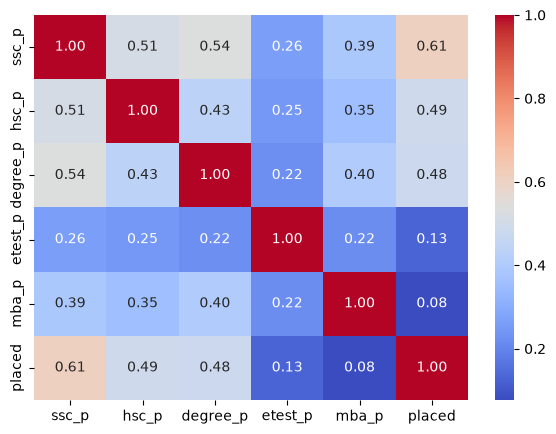

In [6]:
cat_cols = ["gender", "ssc_b", "hsc_b", "hsc_s", "degree_t", "workex", "specialisation"]
for c in cat_cols:
    print(df.groupby(c)["placed"].mean().round(2), "\n")

plt.figure(figsize=(7, 5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()